# EN3160 Assignment 02
## Fitting and Alignment

**Name:** Rahman MFA  
**Index number:** 230507R  
**Repository:** [EN3160 Image Processing and Machine Vision](https://github.com/Abdul-Rahman-bme/EN3160-Image-processing-and-Machine-Vision)


This notebook follows the same question-by-question workflow as Assignment 1. We will run each part, inspect the output, and then write a short discussion based on the actual results.

**Before running:** put the provided Assignment 2 images in the `images` folder next to this notebook.

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

IMAGE_DIR = Path("images/a2images")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Image folder:", IMAGE_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

OpenCV version: 5.0.0
NumPy version: 2.4.6
Image folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\images\a2images
Output folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\outputs


## Q1 — Sunflower blob detection using LoG

We will load the sunflower image at the reduced resolution specified in the assignment. After confirming the image loads correctly, we will implement the LoG scale-space detector. The `cv.HoughCircles()` function will not be used.

Image dimensions (height, width): (360, 360)


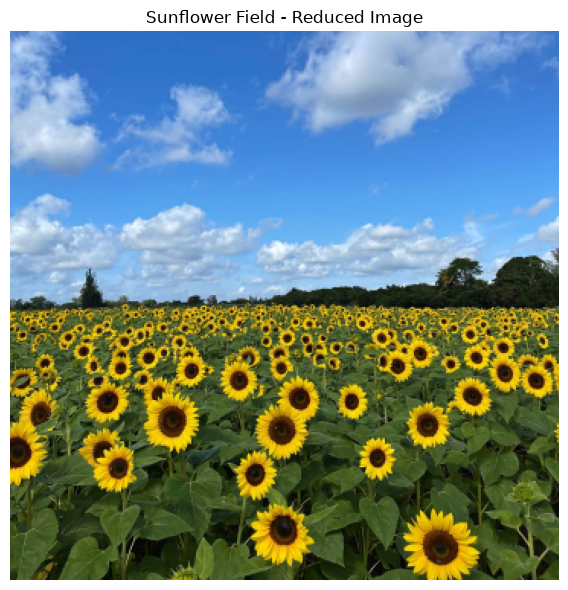

In [4]:
# Q1 - Load and display the sunflower image

sunflower_path = IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"
sunflower = cv.imread(str(sunflower_path), cv.IMREAD_REDUCED_COLOR_4)

if sunflower is None:
    raise FileNotFoundError(
        f"Could not load {sunflower_path.resolve()}. "
        "Check that the image is inside the images folder."
    )

sunflower_rgb = cv.cvtColor(sunflower, cv.COLOR_BGR2RGB)
sunflower_gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY)

print("Image dimensions (height, width):", sunflower_gray.shape)

plt.figure(figsize=(10, 6))
plt.imshow(sunflower_rgb)
plt.title("Sunflower Field - Reduced Image")
plt.axis("off")
plt.tight_layout()
plt.show()

### Q1 — LoG detector

Next, we will test a range of sigma values, calculate the scale-normalized LoG response, detect local extrema across image position and scale, and report the largest detected circles. We will choose the scale range and thresholds after inspecting the image and response values.

## Q2 — RANSAC line and circle fitting

We will generate the noisy point set described in Listing 1 of the assignment. We will implement RANSAC ourselves, estimate a normalized line model first, remove its inliers, and then estimate a circle from the remaining points. The final plot will show the point set, inliers, best samples, estimated models, and ground-truth models.

## Q3 — Homography and image compositing

We will select four points on a planar surface, compute the homography from the flag image to that quadrilateral, warp the flag, and blend it with the architectural image. We will use a couple of image pairs and briefly explain why each surface is suitable.

## Q4 — PCB image alignment

Using `AECC1.jpg` as the template, we will detect SIFT features, match them with `cv.BFMatcher`, estimate a homography with RANSAC, warp each supplied PCB image, and visualize the difference from the template. We will then discuss why some components may show larger differences.

## Report notes

- Keep the final report to four pages or fewer.
- Include the index number and name.
- Show important code, result images, comparisons, and interpretation.
- Commit and push progress regularly.